# 07 — Validation visualization

How we verify the flood map against Sentinel-2, panel by panel:
cloud removal (SCL), the MNDWI water index, the SAR flood map, and the
TP/FP/FN agreement map.


In [1]:
# Setup — run this cell first.
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "code" / "config" / "config.yaml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "code" / "preprocessing"))
print("project root:", ROOT)
"""Visualize the Sentinel-2 validation reference and the SAR-vs-S2 agreement.

Shows, panel by panel, how the reference is built (SCL cloud removal, MNDWI)
and how the SAR flood map compares to it (confusion map). The quantitative
metrics themselves are produced by code/confidence/validate.py; this script
renders them visually.

Outputs: outputs/figures/validation_agreement.png
"""

from __future__ import annotations

import sys
from pathlib import Path


import matplotlib

import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib.colors import ListedColormap
import numpy as np
import rasterio

from common import load_config, rel_path

DB_NODATA = -9999.0
# GMM-based ensemble = the adopted final confidence rule (ADR-23)
METHODS = ["otsu_vv", "otsu_vh", "change_vv", "gmm"]


def read(path):
    with rasterio.open(path) as src:
        return src.read(1)


project root: D:\DIVP PROJECT


## Step 1 — Load the stack and build the analysis domain

In [2]:
cfg = load_config()
processed = rel_path(cfg, "data_processed")
maps = rel_path(cfg, "outputs") / "maps" / "masks"
figures = rel_path(cfg, "outputs") / "figures"
figures.mkdir(parents=True, exist_ok=True)

post_vv = read(processed / "s1_post_vv_db.tif")
slope = read(processed / "slope_deg.tif")
permanent = read(processed / "masks" / "permanent_water.tif")

valid = (post_vv != DB_NODATA) & (slope != DB_NODATA)
base = valid & (permanent == 0)
slope_ok = slope <= cfg["masks"]["slope_deg_max"]
domain = base & slope_ok


## Step 2 — Sentinel-2 reference: cloud removal + MNDWI

In [3]:
# ---- Sentinel-2 reference ----
s2p = rel_path(cfg, "data_raw") / "sentinel2"
b03 = read(s2p / "s2_post_B03.tif").astype("float32")
b11 = read(s2p / "s2_post_B11.tif").astype("float32")
scl = read(s2p / "s2_post_SCL.tif")
clear = np.isin(scl, [2, 4, 5, 6, 7]) & (b03 > 0) & (b11 > 0)
denom = b03 + b11
mndwi = np.full(b03.shape, np.nan, dtype="float32")
ok = clear & (denom > 0)
mndwi[ok] = (b03[ok] - b11[ok]) / denom[ok]
s2_water = np.isfinite(mndwi) & (mndwi > cfg["validation"]["mndwi"]["threshold"]) & domain
evaluable = clear & domain


## Step 3 — SAR flood map (GMM ensemble, k ≥ 2)

In [4]:
# ---- SAR flood map (GMM 4-method, k >= 2) ----
k = sum(read(maps / f"{m}.tif").astype(bool).astype(int) for m in METHODS)
flood = (k >= 2) & domain


## Step 4 — Confusion map (TP / FP / FN / TN)

In [5]:
# ---- confusion (only where Sentinel-2 can see) ----
tp = flood & s2_water & evaluable
fp = flood & ~s2_water & evaluable
fn = ~flood & s2_water & evaluable
tn = ~flood & ~s2_water & evaluable
prec = tp.sum() / (tp.sum() + fp.sum())
rec = tp.sum() / (tp.sum() + fn.sum())
f1 = 2 * prec * rec / (prec + rec)

confusion = np.full(post_vv.shape, -1, dtype="int8")  # -1 = not evaluable
confusion[tn] = 0
confusion[fp] = 1
confusion[fn] = 2
confusion[tp] = 3


## Step 5 — Validation figure

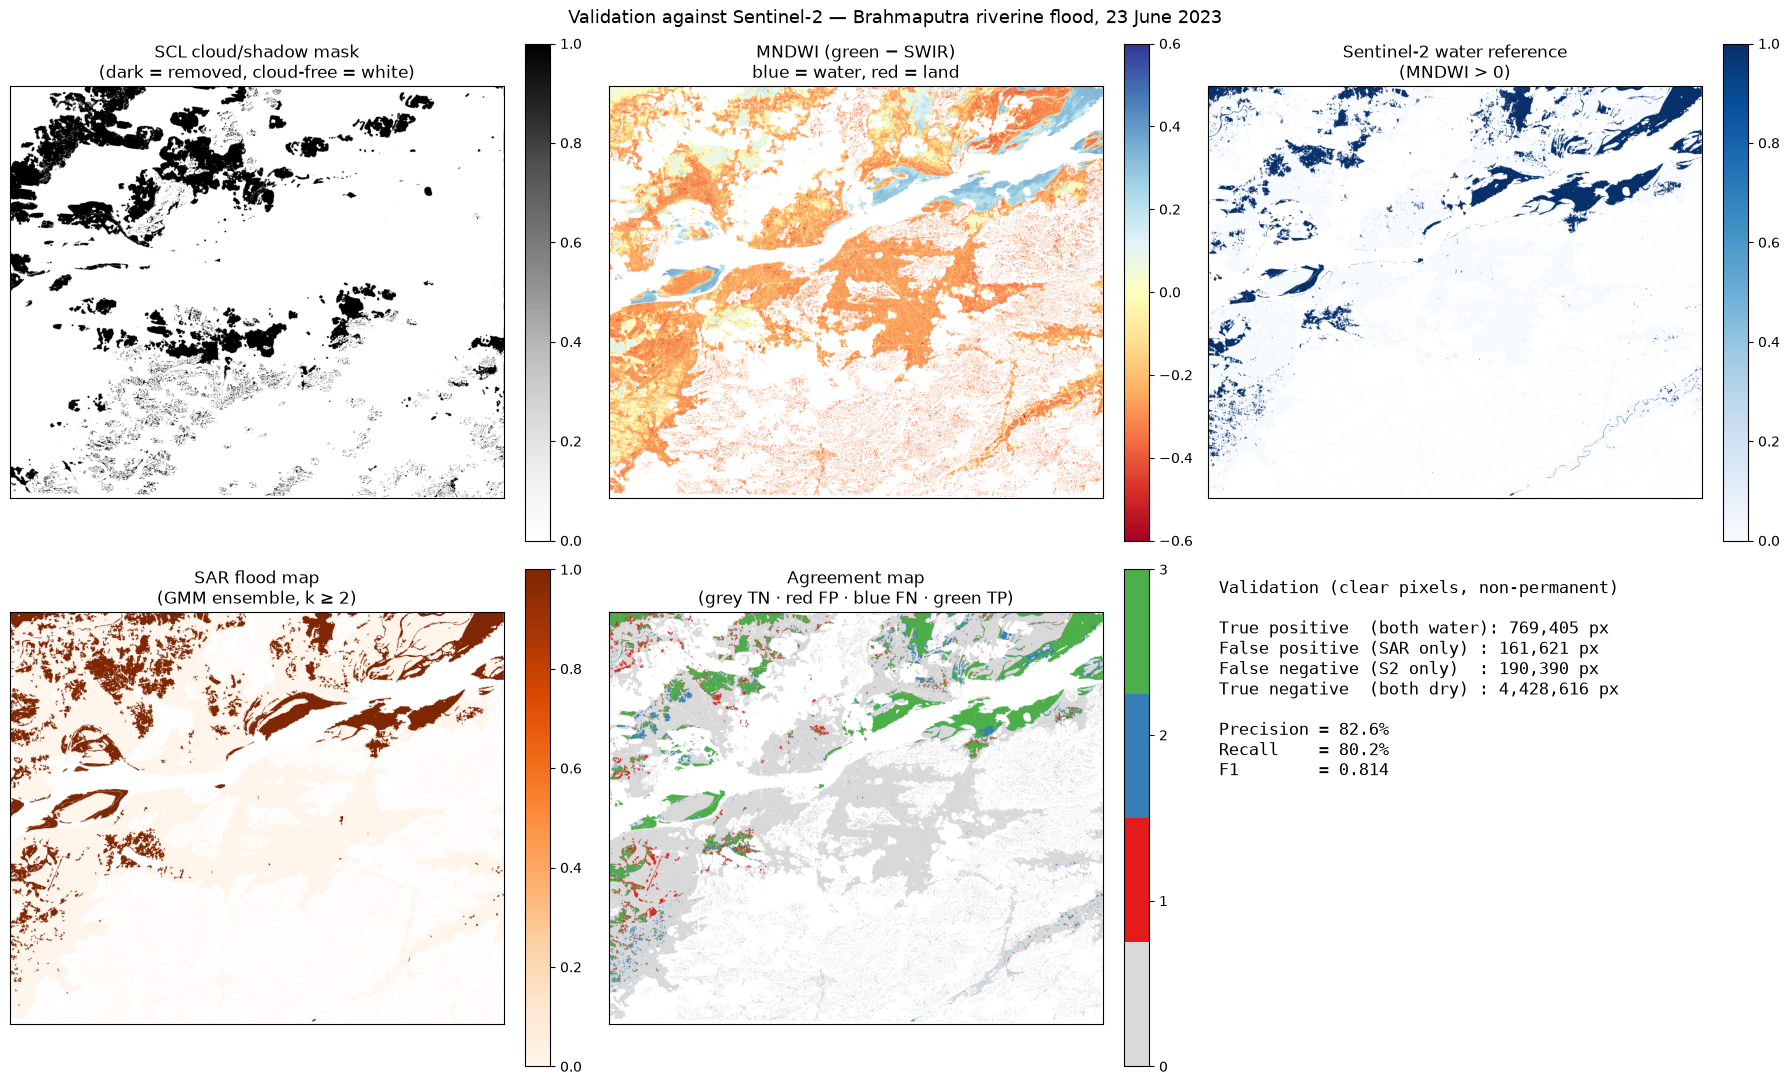

Precision 0.8264, recall 0.8016, F1 0.8138
TP 769405, FP 161621, FN 190390, TN 4428616
Wrote D:\DIVP PROJECT\outputs\figures\validation_agreement.png


In [6]:
# ---- figure ----
cmap_conf = ListedColormap(["#d9d9d9", "#e41a1c", "#377eb8", "#4daf4a"])  # TN FP FN TP

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

im0 = axes[0, 0].imshow(np.where(domain, ~clear, np.nan), cmap="Greys", vmin=0, vmax=1)
axes[0, 0].set_title("SCL cloud/shadow mask\n(dark = removed, cloud-free = white)")
fig.colorbar(im0, ax=axes[0, 0], fraction=0.046, pad=0.04)

im1 = axes[0, 1].imshow(np.where(evaluable, mndwi, np.nan), cmap="RdYlBu", vmin=-0.6, vmax=0.6)
axes[0, 1].set_title("MNDWI (green − SWIR)\nblue = water, red = land")
fig.colorbar(im1, ax=axes[0, 1], fraction=0.046, pad=0.04)

im2 = axes[0, 2].imshow(np.where(evaluable, s2_water, np.nan), cmap="Blues", vmin=0, vmax=1)
axes[0, 2].set_title("Sentinel-2 water reference\n(MNDWI > 0)")
fig.colorbar(im2, ax=axes[0, 2], fraction=0.046, pad=0.04)

im3 = axes[1, 0].imshow(np.where(domain, flood, np.nan), cmap="Oranges", vmin=0, vmax=1)
axes[1, 0].set_title("SAR flood map\n(GMM ensemble, k ≥ 2)")
fig.colorbar(im3, ax=axes[1, 0], fraction=0.046, pad=0.04)

im4 = axes[1, 1].imshow(np.where(confusion >= 0, confusion, np.nan), cmap=cmap_conf, vmin=0, vmax=3)
axes[1, 1].set_title("Agreement map\n(grey TN · red FP · blue FN · green TP)")
fig.colorbar(im4, ax=axes[1, 1], fraction=0.046, pad=0.04,
             ticks=[0, 1, 2, 3])

axes[1, 2].axis("off")
summary = (
    f"Validation (clear pixels, non-permanent)\n\n"
    f"True positive  (both water): {tp.sum():,} px\n"
    f"False positive (SAR only) : {fp.sum():,} px\n"
    f"False negative (S2 only)  : {fn.sum():,} px\n"
    f"True negative  (both dry) : {tn.sum():,} px\n\n"
    f"Precision = {prec * 100:.1f}%\n"
    f"Recall    = {rec * 100:.1f}%\n"
    f"F1        = {f1:.3f}"
)
axes[1, 2].text(0.02, 0.98, summary, va="top", ha="left", fontsize=12, family="monospace")

for ax in axes.ravel()[:5]:
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle(f"Validation against Sentinel-2 — {cfg['event']['name']}", fontsize=13)
fig.tight_layout()
fig_path = figures / "validation_agreement.png"
fig.savefig(fig_path, dpi=140)
plt.show()
plt.close(fig)

print(f"Precision {prec:.4f}, recall {rec:.4f}, F1 {f1:.4f}")
print(f"TP {tp.sum()}, FP {fp.sum()}, FN {fn.sum()}, TN {tn.sum()}")
print(f"Wrote {fig_path}")
